# EDA & Feature Engineering

## 1. Thiết lập

Mở notebook từ thư mục dự án hoặc `notebooks/`. Các gói cần thiết nằm trong `requirements.txt`.

In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

_here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [_here, *_here.parents]
                     if (p / "src" / "preprocessing").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy urban-air-quality-mining/src/preprocessing")
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from preprocessing.loading import load_hourly_data
from preprocessing.features import prepare_hourly_data
from preprocessing.model_ready import prepare_model_ready_dataset
from preprocessing.schema import (
    RAW_MEASUREMENT_COLUMNS, MODEL_INPUT_COLUMNS, CANDIDATE_FEATURE_COLUMNS,
    SELECTED_FEATURE_COLUMNS, TARGET_COLUMN, MODELING_LOCATION,
    FEATURE_SELECTION_REASONS, EXCLUDED_FEATURE_REASONS,
)
from eda_workflow.profile import build_profile

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "openaq_cmt8_2y_hourly.csv"
raw, load_report = load_hourly_data(DATA_PATH)
profile = build_profile(raw)

print(f"Nguồn: {DATA_PATH.name}")
print(f"Thời gian: {raw['datetime'].min()} → {raw['datetime'].max()}")
print(f"Số giờ trên lưới: {len(raw):,}; số segment metadata: {raw['location_segment_id'].nunique()}")
print(f"Giờ không có phép đo nào: {profile['overview']['hours_with_no_measurement']:,}")

Nguồn: openaq_cmt8_2y_hourly.csv
Thời gian: 2024-11-19 18:00:00+07:00 → 2026-11-11 00:00:00+07:00
Số giờ trên lưới: 17,311; số segment metadata: 2
Giờ không có phép đo nào: 1,342


## 2. Đọc phạm vi và vị trí dữ liệu

,location_segment_id,location,latitude,longitude,start_datetime,end_datetime,hour_rows,pm2_5_observed,pm10_observed
0,0,One Verandah Ciel 13th floor-3246311,10.77698,106.751552,2024-11-19T18:00:00+07:00,2025-02-13T00:00:00+07:00,2047,1285,1261
1,1,CMT8-3246311,10.78533,106.670290,2025-02-13T01:00:00+07:00,2026-11-11T00:00:00+07:00,15264,14684,0


,location_segment_id,location,observed,median,q1,q3
0,0,One Verandah Ciel 13th floor-3246311,1285,38.49,27.15,51.16
1,1,CMT8-3246311,14684,29.10,20.70,38.61


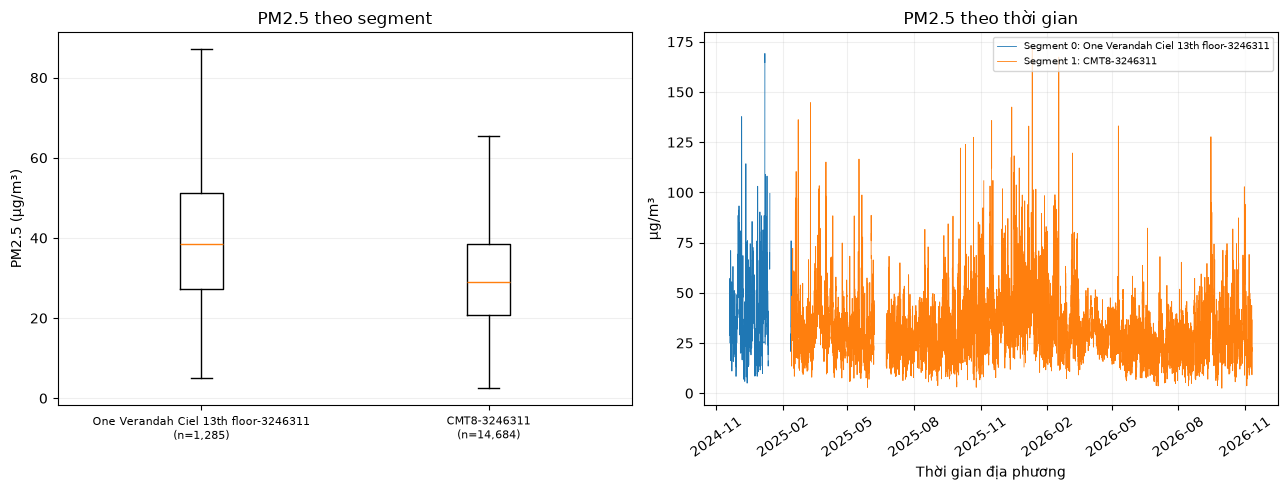

In [3]:
segments = profile["location_segments"].copy()
segment_stats = raw.groupby(["location_segment_id", "location"], dropna=False)["pm2_5_ug_m3"].agg(
    observed="count", median="median", q1=lambda x: x.quantile(.25), q3=lambda x: x.quantile(.75)
).reset_index()
display(segments)
display(segment_stats.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
labels = [f"{r.location}\n(n={r.observed:,})" for r in segment_stats.itertuples()]
axes[0].boxplot([g["pm2_5_ug_m3"].dropna().to_numpy() for _, g in raw.groupby("location_segment_id", sort=True)],
                tick_labels=labels, showfliers=False)
axes[0].set(title="PM2.5 theo segment", ylabel="PM2.5 (µg/m³)")
axes[0].tick_params(axis="x", labelsize=8); axes[0].grid(axis="y", alpha=.2)
for sid, g in raw.groupby("location_segment_id", sort=True):
    axes[1].plot(g["datetime"], g["pm2_5_ug_m3"], lw=.6, label=f"Segment {sid}: {g['location'].iloc[0]}")
axes[1].set(title="PM2.5 theo thời gian", xlabel="Thời gian địa phương", ylabel="µg/m³")
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[1].tick_params(axis="x", rotation=35); axes[1].grid(alpha=.2); axes[1].legend(fontsize=7)
fig.tight_layout(); plt.show()

**Nhận xét** Có hai segment: vị trí cũ *One Verandah Ciel 13th floor-3246311* và `CMT8-3246311`. Hai phần có tọa độ và phân phối PM2.5 khác nhau. EDA giữ cả hai để kiểm tra, còn pipeline mô hình lọc riêng CMT8 vì chiếm phần lớn data.

## 3. Độ đầy đủ và khoảng trống theo thời gian

- Heatmap chỉ ra biến/tháng bị thiếu
- Gap summary cho biết thiếu rời rạc hay kéo dài.

=> Đây là căn cứ để chọn cách xử lý. Đặc biệt, cần phân biệt timestamp không có trong nguồn với một giờ có timestamp nhưng cảm biến không trả số đo.

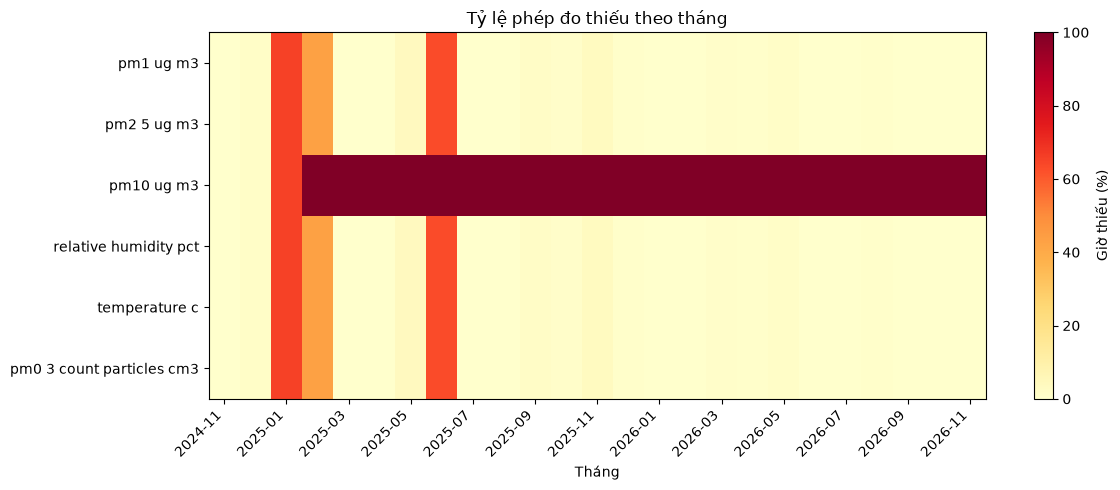

,location_segment_id,location,measurement,missing_hours,missing_pct,missing_gap_count,longest_missing_gap_hours
8,1,CMT8-3246311,pm10_ug_m3,15264,100.000000,1,15264
2,0,One Verandah Ciel 13th floor-3246311,pm10_ug_m3,786,38.397655,11,714
1,0,One Verandah Ciel 13th floor-3246311,pm2_5_ug_m3,762,37.225208,11,690
0,0,One Verandah Ciel 13th floor-3246311,pm1_ug_m3,762,37.225208,11,690
3,0,One Verandah Ciel 13th floor-3246311,relative_humidity_pct,762,37.225208,11,690
4,0,One Verandah Ciel 13th floor-3246311,temperature_c,762,37.225208,11,690
5,0,One Verandah Ciel 13th floor-3246311,pm0_3_count_particles_cm3,762,37.225208,11,690
6,1,CMT8-3246311,pm1_ug_m3,580,3.799790,51,393
7,1,CMT8-3246311,pm2_5_ug_m3,580,3.799790,51,393
9,1,CMT8-3246311,relative_humidity_pct,580,3.799790,51,393


,observed,missing,missing_pct
pm1_ug_m3,15969,1342,7.75
pm2_5_ug_m3,15969,1342,7.75
relative_humidity_pct,15969,1342,7.75
temperature_c,15969,1342,7.75
pm0_3_count_particles_cm3,15969,1342,7.75
pm10_ug_m3,1261,16050,92.72


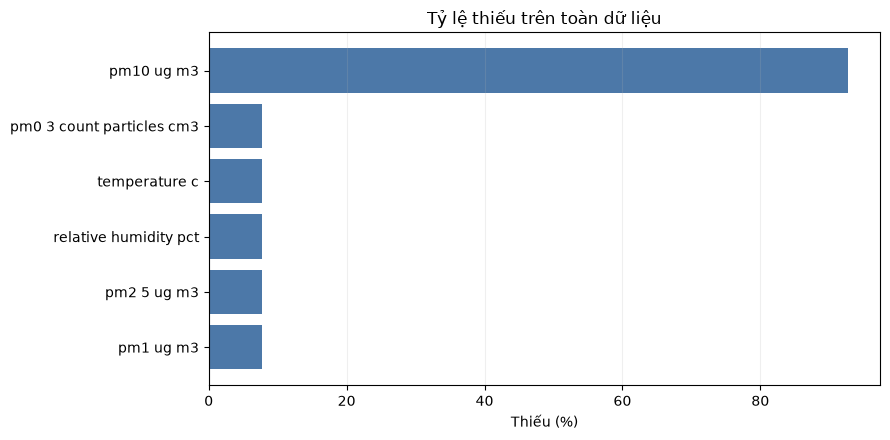

In [4]:
monthly = profile["monthly_missing_pct"]
fig, ax = plt.subplots(figsize=(max(12, len(monthly) * .42), 5))
img = ax.imshow(monthly.T, aspect="auto", interpolation="nearest", cmap="YlOrRd", vmin=0, vmax=100)
ax.set_yticks(range(len(monthly.columns)), [c.replace("_", " ") for c in monthly.columns])
step = max(1, len(monthly) // 12)
ticks = list(range(0, len(monthly), step))
ax.set_xticks(ticks, [monthly.index[i] for i in ticks], rotation=45, ha="right")
ax.set_title("Tỷ lệ phép đo thiếu theo tháng"); ax.set_xlabel("Tháng")
fig.colorbar(img, ax=ax, label="Giờ thiếu (%)"); fig.tight_layout(); plt.show()

gaps = profile["missing_gap_summary_by_segment"].sort_values("longest_missing_gap_hours", ascending=False)
display(gaps[["location_segment_id", "location", "measurement", "missing_hours", "missing_pct", "missing_gap_count", "longest_missing_gap_hours"]].head(16))
coverage = pd.DataFrame({
    "observed": raw[RAW_MEASUREMENT_COLUMNS].notna().sum(),
    "missing": raw[RAW_MEASUREMENT_COLUMNS].isna().sum(),
    "missing_pct": (100 * raw[RAW_MEASUREMENT_COLUMNS].isna().mean()).round(2),
}).sort_values("missing_pct")
display(coverage)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(coverage.index.str.replace("_", " "), coverage["missing_pct"], color="#4C78A8")
ax.set(title="Tỷ lệ thiếu trên toàn dữ liệu", xlabel="Thiếu (%)")
ax.grid(axis="x", alpha=.2); fig.tight_layout(); plt.show()

**Nhận xét** PM1, PM2.5, độ ẩm, nhiệt độ và PM0.3 cùng thiếu 1,342/17,311 giờ (7.75%); tại CMT8 có gap chung dài nhất 393 giờ. PM10 thiếu 92.72% toàn tập và 100% ở CMT8. Loader không phải thêm giờ mới vào lưới, nhưng có 1,342 hàng giờ mà mọi phép đo đều trống.

Vì thiếu hụt đồng thời và có gap dài nên ta không nội suy xuyên outage dài; PM10 giữ cho EDA nhưng không đưa vào baseline vì khuyết hoàn toàn ở CMT8. Các phép đo gốc tiếp tục được giữ để kiểm toán.

## 4. Kiểm tra thuộc tính khí tượng

Đề tài gợi ý nhiệt độ, độ ẩm, áp suất, tốc độ gió và hướng gió. Ta kiểm tra trực tiếp các cột nguồn, thay vì giả định rằng mọi biến này đều có trong dataset.

,Thuộc tính,Cột nguồn,Quan trắc,Độ phủ (%)
0,Nhiệt độ,temperature_c,15969,92.2
1,Độ ẩm tương đối,relative_humidity_pct,15969,92.2
2,Áp suất,Không có,0,0.0
3,Tốc độ gió,Không có,0,0.0
4,Hướng gió,Không có,0,0.0
5,Mưa,Không có,0,0.0


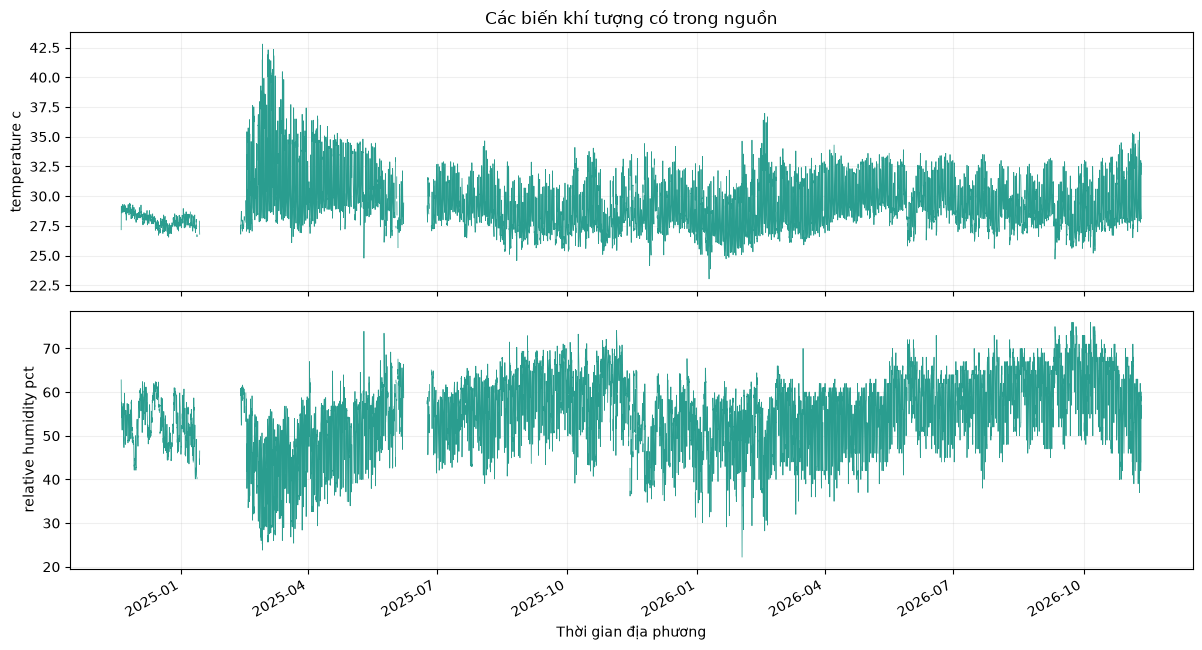

In [20]:
weather_candidates = {
    "Nhiệt độ": ["temperature_c", "temperature", "temp"],
    "Độ ẩm tương đối": ["relative_humidity_pct", "relativehumidity", "humidity"],
    "Áp suất": ["pressure", "pressure_hpa", "surface_pressure"],
    "Tốc độ gió": ["wind_speed", "windspeed", "wspd"],
    "Hướng gió": ["wind_direction", "winddirection", "wd"],
    "Mưa": ["rain", "precipitation", "precip"],
}
weather_rows = []
for name, aliases in weather_candidates.items():
    matches = [col for col in aliases if col in raw.columns]
    col = matches[0] if matches else None
    weather_rows.append({
        "Thuộc tính": name,
        "Cột nguồn": col or "Không có",
        "Quan trắc": int(raw[col].notna().sum()) if col else 0,
        "Độ phủ (%)": round(100 * raw[col].notna().mean(), 1) if col else 0,
    })
weather_inventory = pd.DataFrame(weather_rows)
display(weather_inventory)

available_weather = [c for c in ["temperature_c", "relative_humidity_pct"] if c in raw.columns]
fig, axes = plt.subplots(len(available_weather), 1, figsize=(12, 3.3 * len(available_weather)), sharex=True)
if len(available_weather) == 1: axes = [axes]
for ax, col in zip(axes, available_weather):
    ax.plot(raw["datetime"], raw[col], lw=.55, color="#2A9D8F")
    ax.set_ylabel(col.replace("_", " ")); ax.grid(alpha=.2)
axes[0].set_title("Các biến khí tượng có trong nguồn")
axes[-1].set_xlabel("Thời gian địa phương"); fig.autofmt_xdate(); fig.tight_layout(); plt.show()

Nguồn có nhiệt độ và độ ẩm nhưng lại không có áp suất, gió, hướng gió hay mưa. Không thể xử lý biến không có trong nguồn bằng imputation và nếu muốn thêm phải ghép nguồn ngoài theo đúng trạm, giờ và đơn vị.

## 5. Phân phối, ngoại biên và tương quan ban đầu

Các biểu đồ trong mục này dùng toàn giai đoạn và cả hai segment để mô tả dữ liệu ban đầu. Chúng giúp nhận diện dạng phân phối, điểm cần rà soát và quan hệ tuyến tính; chưa dùng để kết luận nhân quả hoặc chọn biến cho mô hình.


### 5.1. Phân phối các phép đo

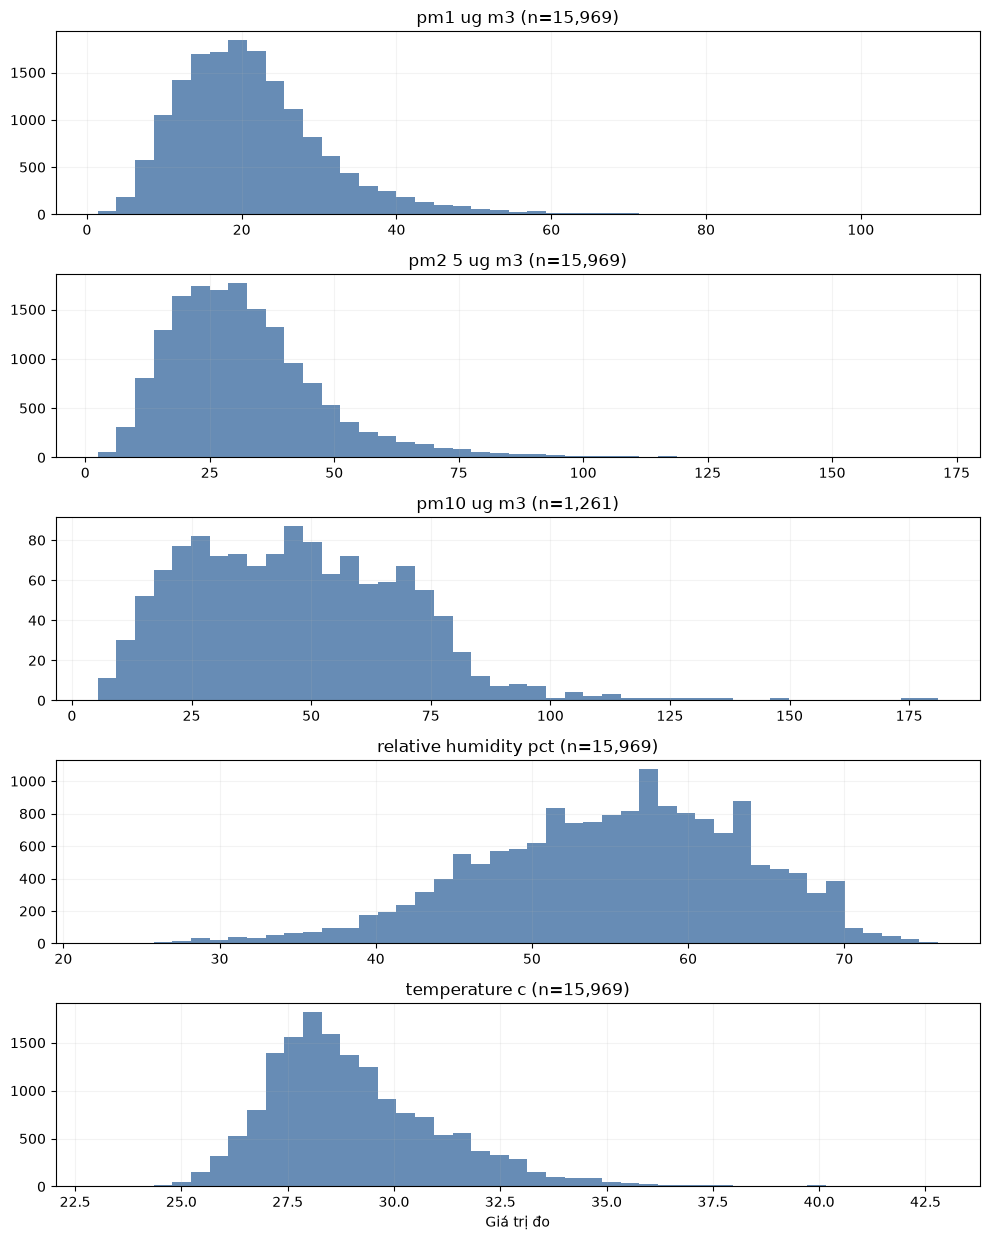

In [21]:
numeric_cols = ["pm1_ug_m3", "pm2_5_ug_m3", "pm10_ug_m3", "relative_humidity_pct", "temperature_c"]
fig, axes = plt.subplots(len(numeric_cols), 1, figsize=(10, 2.5 * len(numeric_cols)))
for ax, col in zip(axes, numeric_cols):
    values = raw[col].dropna()
    ax.hist(values, bins=45, color="#4C78A8", alpha=.85)
    ax.set_title(f"{col.replace('_', ' ')} (n={len(values):,})"); ax.grid(alpha=.15)
axes[-1].set_xlabel("Giá trị đo"); fig.tight_layout(); plt.show()



**Nhận xét các biểu đồ phân phối**

- **PM1:** phân phối lệch phải, tập trung nhiều ở vùng thấp hơn và có đuôi giá trị cao.
- **PM2.5:** cũng có đuôi phải và một số quan trắc cao; các đỉnh này có thể là sự kiện ô nhiễm, nên chưa xóa/cắt ngọn chỉ dựa trên histogram.
- **PM10:** histogram chỉ phản ánh các giờ có số đo; PM10 thiếu dữ liệu nhiều nên phân phối quan sát được có độ phủ thấp hơn các biến còn lại.
- **Độ ẩm và nhiệt độ:** mỗi biến có thang đo và vùng giá trị riêng; đọc hình dạng theo trục riêng, không so sánh trị số trực tiếp với nồng độ bụi.

Các histogram là phân phối biên, không thể hiện thời điểm xảy ra các giá trị cao. Phần IQR bên dưới sẽ đặt các điểm PM2.5 bị gắn cờ trở lại trên chuỗi thời gian để rà soát.


### 5.2. Heatmap tương quan giữa phép đo

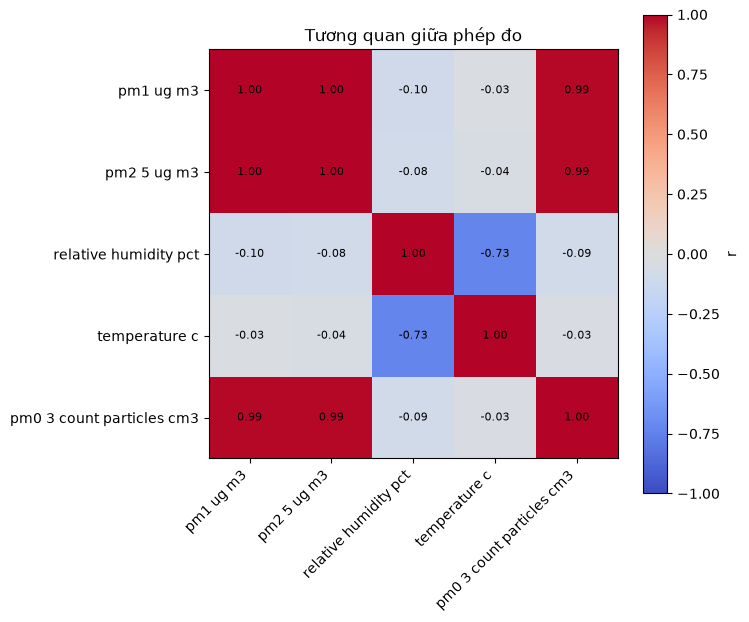

In [7]:
raw_corr_cols = ["pm1_ug_m3", "pm2_5_ug_m3", "relative_humidity_pct", "temperature_c", "pm0_3_count_particles_cm3"]
raw_corr = raw[raw_corr_cols].corr(min_periods=24)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
img = ax.imshow(raw_corr, cmap="coolwarm", vmin=-1, vmax=1)
labels = [c.replace("_", " ") for c in raw_corr_cols]
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right"); ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        value = raw_corr.iloc[i, j]
        ax.text(j, i, "NA" if pd.isna(value) else f"{value:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Tương quan giữa phép đo")
fig.colorbar(img, ax=ax, label="r"); fig.tight_layout(); plt.show()

**Nhận xét**

- PM1 và PM0.3 có tương quan dương mạnh với PM2.5, gợi ý các phép đo bụi có thể mang thông tin chồng lấp.
- Độ ẩm và nhiệt độ có liên hệ tuyến tính đáng chú ý; đây là cơ sở để xem xét khả năng dư thừa giữa hai thuộc tính khí tượng.
- Đây là tương quan Pearson trên dữ liệu gộp cả giai đoạn và hai segment. Tương quan không chứng minh nhân quả; khác biệt độ phủ cũng có thể làm thay đổi số cặp dùng trong từng hệ số.

### 5.3. Rà soát ngoại biên PM2.5 bằng IQR

,location_segment_id,location,observed,lower_fence,upper_fence,iqr_outlier_count
1,0,One Verandah Ciel 13th floor-3246311,1285,-8.859687,87.166145,32
7,1,CMT8-3246311,14684,-6.167000,65.478333,494


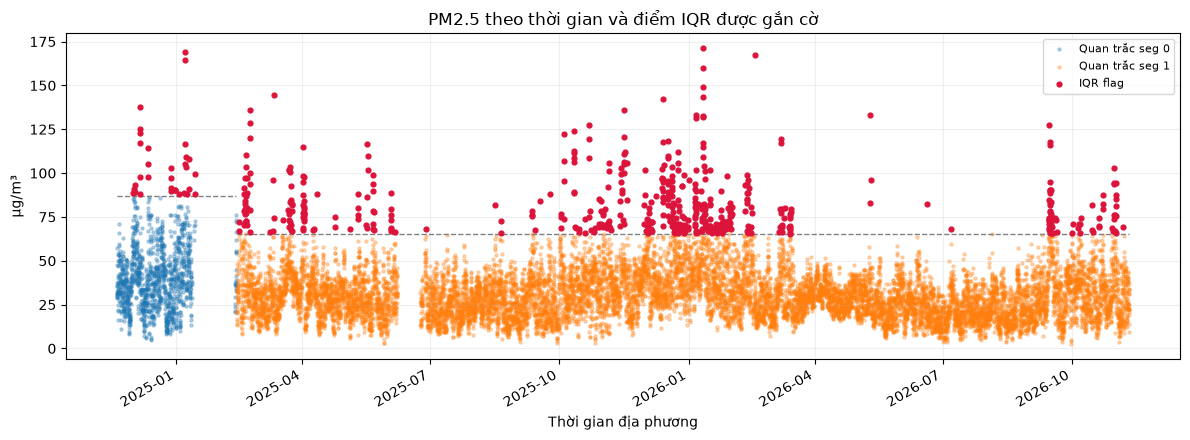

In [9]:
outlier_summary = profile["outlier_summary_by_segment"]
pm25_outliers = outlier_summary.loc[outlier_summary["measurement"].eq("pm2_5_ug_m3")]
pm25_events = profile["outlier_events_by_segment"].query("measurement == 'pm2_5_ug_m3'").copy()
if not pm25_events.empty: pm25_events["datetime"] = pd.to_datetime(pm25_events["datetime"])
display(pm25_outliers[["location_segment_id", "location", "observed", "lower_fence", "upper_fence", "iqr_outlier_count"]])
fig, ax = plt.subplots(figsize=(12, 4.5))
for sid, group in raw.groupby("location_segment_id", sort=True):
    ax.scatter(group["datetime"], group["pm2_5_ug_m3"], s=5, alpha=.3, label=f"Quan trắc seg {sid}")
    fence = pm25_outliers.loc[pm25_outliers["location_segment_id"].eq(sid)]
    if not fence.empty:
        ax.hlines(fence.iloc[0]["upper_fence"], group["datetime"].min(), group["datetime"].max(), color="gray", ls="--", lw=1)
if not pm25_events.empty:
    ax.scatter(pm25_events["datetime"], pm25_events["value"], color="crimson", s=12, label="IQR flag", zorder=3)
ax.set(title="PM2.5 theo thời gian và điểm IQR được gắn cờ", xlabel="Thời gian địa phương", ylabel="µg/m³")
ax.grid(alpha=.2); ax.legend(fontsize=8); fig.autofmt_xdate(); fig.tight_layout(); plt.show()

**Nhận xét** 
- Quy tắc IQR gắn cờ 32 điểm PM2.5 ở segment cũ và 494 điểm ở CMT8.
- Các điểm vượt ngưỡng là những giá trị cao cần rà soát trên trục thời gian, nhưng có thể phản ánh sự kiện ô nhiễm thật.
=> Nên giữ nguyên giá trị và chỉ gắn cờ


## 6. Thực nghiệm so sánh ffill 1–4 giờ

Đánh giá chính sách điền thiếu trước khi chốt ngưỡng ffill dùng cho baseline, tạo candidate features hoặc chọn các biến đầu vào. Thử các giới hạn 1–4 giờ trực tiếp trên raw CMT8, chỉ tính ảnh hưởng trên đoạn train:

1. Đếm số giá trị/giờ được lấp và số cặp đầu vào PM2.5–target quan sát còn dùng được.
2. Giả lập gap liên tục trên các cửa sổ vốn có số đo thật: carry số đo cuối trước gap tới giờ thứ `h`, so với số đo thật đã che. Đây là sai số proxy của giá trị cũ, không phải RMSE của model.

Ranh giới train được tính từ timeline CMT8 (`target_datetime = datetime + 1h`), không phụ thuộc vào bất kỳ feature hoặc baseline nào.

Validation begins at: 2026-05-04 06:00:00+07:00


,ffill limit (h),PM2.5 cells filled,Temperature cells filled,All five input cells filled,Train PM2.5-input/target pairs,Train PM2.5+temp+target rows,Additional PM2.5+temp rows,N train,MAE,RMSE
0,1,44,44,220,10099,10099,0,10074,5.13,8.17
1,2,64,64,320,10102,10102,3,10031,7.92,11.92
2,3,81,81,405,10106,10106,4,9988,9.82,14.26
3,4,94,94,470,10106,10106,0,9951,11.23,15.91


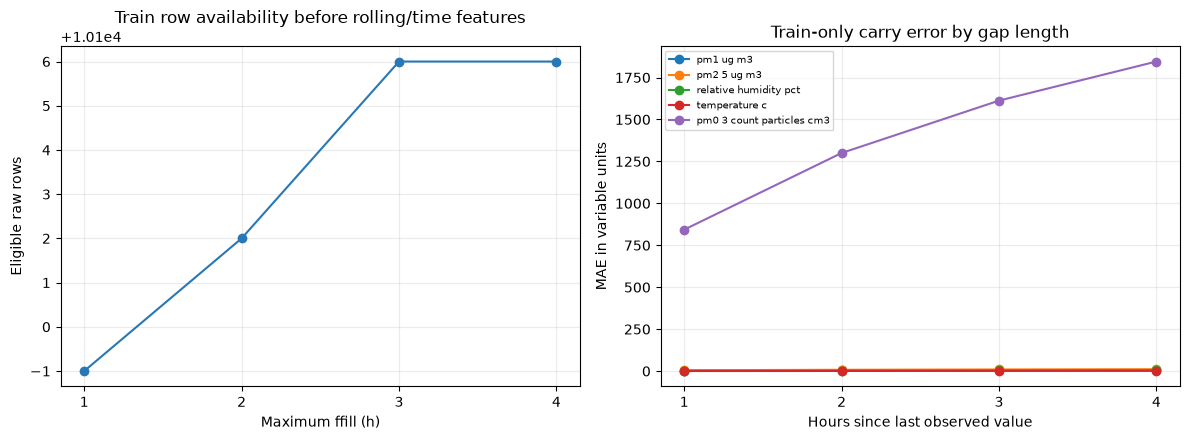

In [10]:
limits=(1,2,3,4)
site_raw=raw.loc[raw["location"].eq(MODELING_LOCATION)].sort_values(["location_segment_id","datetime"]).copy()
site_raw["target_datetime"] = site_raw["datetime"] + pd.Timedelta(hours=1)
target_times=site_raw["target_datetime"].dropna().drop_duplicates().sort_values().reset_index(drop=True)
train_end=min(max(int(len(target_times)*.70),1),len(target_times)-2)
validation_start=target_times.iloc[train_end]
train_mask=(site_raw["target_datetime"] < validation_start)
target_next=site_raw.groupby("location_segment_id",sort=False)["pm2_5_ug_m3"].shift(-1)

coverage_rows=[]
for limit_hours in limits:
    filled_inputs={}
    for col in MODEL_INPUT_COLUMNS:
        if limit_hours == 0:
            filled_inputs[col]=site_raw[col]
        else:
            filled_inputs[col]=site_raw.groupby("location_segment_id",sort=False)[col].ffill(limit=limit_hours)
    pm25_input=filled_inputs["pm2_5_ug_m3"]
    temp_input=filled_inputs["temperature_c"]
    input_target_pair=train_mask & pm25_input.notna() & target_next.notna()
    pm25_temp_target=train_mask & pm25_input.notna() & temp_input.notna() & target_next.notna()
    # Ffill cell counts are restricted to the train window as well.
    filled_counts={col:int((site_raw[col].isna() & filled_inputs[col].notna() & train_mask).sum()) for col in MODEL_INPUT_COLUMNS}
    coverage_rows.append({
        "ffill limit (h)":limit_hours,
        "PM2.5 cells filled":filled_counts["pm2_5_ug_m3"],
        "Temperature cells filled":filled_counts["temperature_c"],
        "All five input cells filled":sum(filled_counts.values()),
        "Train PM2.5-input/target pairs":int(input_target_pair.sum()),
        "Train PM2.5+temp+target rows":int(pm25_temp_target.sum()),
    })
coverage_compare=pd.DataFrame(coverage_rows)
coverage_compare["Additional PM2.5+temp rows"] = coverage_compare["Train PM2.5+temp+target rows"].diff().fillna(0).astype(int)

# Determine the chronological cutoff without calling feature generation or model-ready code.
train_raw=site_raw.loc[train_mask].sort_values(["location_segment_id","datetime"])
sim_rows=[]
for variable in MODEL_INPUT_COLUMNS:
    values=train_raw[variable]
    grouped=values.groupby(train_raw["location_segment_id"],sort=False)
    for h in limits:
        carried=grouped.shift(h)
        middle_observed=pd.Series(True,index=train_raw.index)
        for lag in range(1,h): middle_observed &= grouped.shift(lag).notna()
        eligible=values.notna() & carried.notna() & middle_observed
        errors=values.loc[eligible]-carried.loc[eligible]
        sim_rows.append({"Variable":variable,"Gap length (h)":h,"N train":int(len(errors)),
                         "MAE":float(errors.abs().mean()),"RMSE":float(np.sqrt((errors**2).mean())),
                         "P90 absolute error":float(errors.abs().quantile(.90))})
sim_errors=pd.DataFrame(sim_rows)
pm25_error=sim_errors.loc[sim_errors["Variable"].eq("pm2_5_ug_m3"),["Gap length (h)","N train","MAE","RMSE"]]
ffill_comparison=coverage_compare.merge(pm25_error,left_on="ffill limit (h)",right_on="Gap length (h)").drop(columns="Gap length (h)")
print("Validation begins at:",validation_start)
display(ffill_comparison.round(2))

fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].plot(coverage_compare["ffill limit (h)"],coverage_compare["Train PM2.5+temp+target rows"],marker="o",color="#2878B5")
axes[0].set(title="Train row availability before rolling/time features",xlabel="Maximum ffill (h)",ylabel="Eligible raw rows")
axes[0].set_xticks(limits); axes[0].grid(alpha=.25)
for variable,g in sim_errors.groupby("Variable",sort=False):
    axes[1].plot(g["Gap length (h)"],g["MAE"],marker="o",label=variable.replace("_"," "))
axes[1].set(title="Train-only carry error by gap length",xlabel="Hours since last observed value",ylabel="MAE in variable units")
axes[1].set_xticks(limits); axes[1].grid(alpha=.25); axes[1].legend(fontsize=7)
fig.tight_layout(); plt.show()

## 7. Chốt ngưỡng ffill dùng cho baseline

Trong train CMT8, ffill 1/2/3/4 giờ lần lượt lấp **44/64/81/94 giá trị PM2.5**. Carry càng lâu thì sai số giả lập càng tăng; với PM2.5, MAE khoảng **5.13/7.92/9.82/11.23 µg/m³** ở gap 1/2/3/4 giờ. Sau khi chốt ngưỡng ở đây, các cell feature engineering phía dưới mới dùng ngưỡng đó.

**Lý do chọn trần 2 giờ thay vì 3–4:** số cặp raw hữu ích tăng ít dần sau 2 giờ, trong khi phép đo được mang carry ngày càng cũ. Đây là ngưỡng thận trọng cho các gap ngắn, không phải nội suy dài hay lựa chọn tối ưu phổ quát. **1 giờ ít sai số hơn** và là lựa chọn phù hợp nếu ưu tiên tuyệt đối độ trung thực; giữ 2 giờ là đánh đổi để thu thêm một ít dữ liệu.

Mô phỏng che gap chỉ dùng các chuỗi vốn có quan trắc liên tục trong train. Gap thực có thể không ngẫu nhiên, nên đây là bằng chứng về mức stale-value theo thời lượng, không phải ground truth sai số tại các giờ đã mất.


## 8. Tạo feature

- Cell dưới gọi `prepare_hourly_data`, nơi code tạo input ffill nhân quả, biến thời gian dạng sin/cos, lag, rolling và target kế tiếp.
- Các giá trị raw không bị ghi đè kèm cờ ffill giữ dấu vết nguồn gốc. 
- PM10 không điền và target PM2.5 `t+1` chỉ lấy từ quan trắc thật.

In [11]:
MAX_CAUSAL_FILL_HOURS = 2
ROLLING_WINDOW_HOURS = 24
ROLLING_MIN_OBSERVATIONS = 18
featured, feature_report = prepare_hourly_data(
    raw,
    max_causal_fill_hours=MAX_CAUSAL_FILL_HOURS,
    rolling_window_hours=ROLLING_WINDOW_HOURS,
    rolling_min_observations=ROLLING_MIN_OBSERVATIONS,
)
print("Causal fill counts:", feature_report["forward_filled_input_values"])
print("Feature count candidates:", len(CANDIDATE_FEATURE_COLUMNS))
print("Selected baseline (configured):", len(SELECTED_FEATURE_COLUMNS))
print("Target:", TARGET_COLUMN, "(observed; not imputed)")

Causal fill counts: {'pm1_ug_m3': 93, 'pm2_5_ug_m3': 93, 'relative_humidity_pct': 93, 'temperature_c': 93, 'pm0_3_count_particles_cm3': 93}
Feature count candidates: 19
Selected baseline (configured): 7
Target: target_pm2_5_next_hour (observed; not imputed)


### Feature groups được sinh

- **Causal/current:** PM1, PM2.5, độ ẩm, nhiệt độ, PM0.3 và cờ cho biết ô đã ffill.
- **Lịch sử:** PM2.5 lag 1/3/24 giờ; PM1, độ ẩm, nhiệt độ, PM0.3 lag 1 giờ; rolling PM2.5 24 giờ và số quan trắc thật.
- **Thời gian:** hour/day-of-week/month và các cặp sin/cos.
- **Target:** `target_pm2_5_next_hour` là giá trị phép đo thật ở giờ kế tiếp.

Candidate chưa phải là model input cuối. Việc chọn baseline sẽ thực hiện sau khi đo tương quan trên train.

## 9. Kiểm tra feature ffill và rolling

Hai hình dưới giúp kiểm tra giá trị nào được carry và lúc nào rolling đủ độ phủ. Đường ffill không phải nội suy giữa hai đầu mút; rolling không dùng giá trị đã được carry để tăng giả tạo số phép đo.

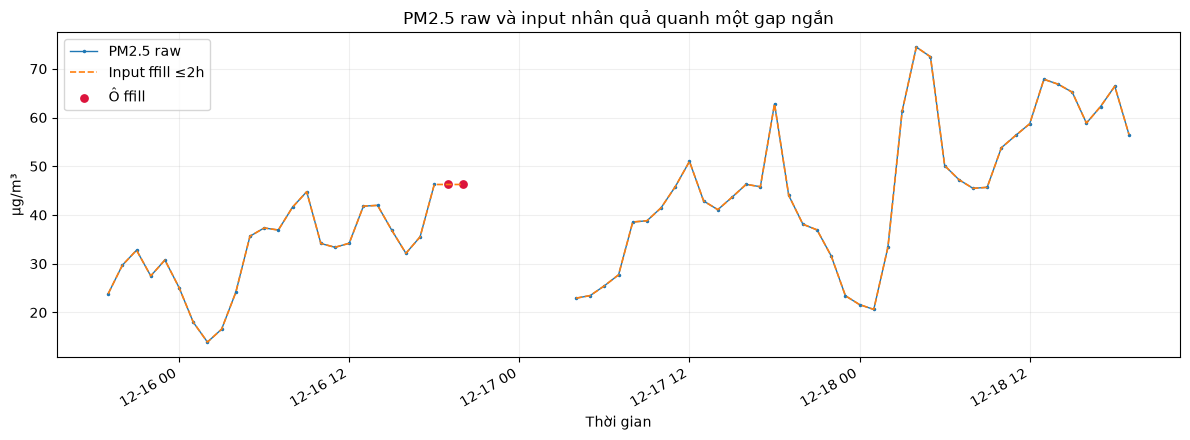

CMT8 rolling windows đủ 18/24: 14,647/15,264 (95.96%)


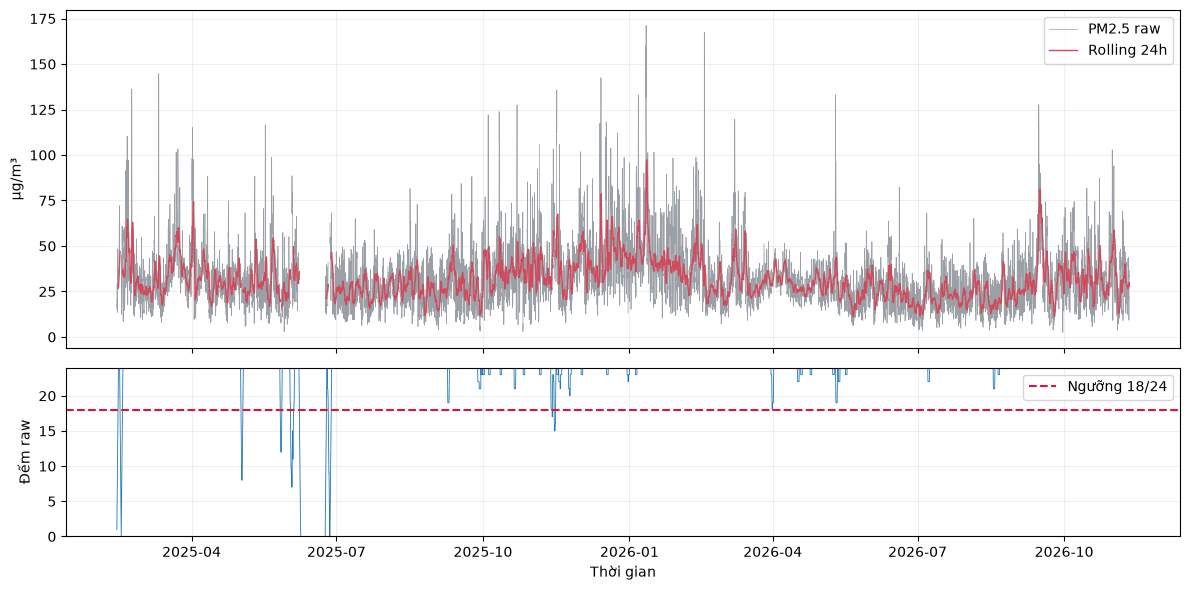

In [12]:
fill_flag = "pm2_5_ug_m3_was_forward_filled"
filled_rows = featured.loc[featured[fill_flag], "datetime"]
center = filled_rows.iloc[0] if len(filled_rows) else raw.loc[raw["pm2_5_ug_m3"].isna(), "datetime"].iloc[0]
window_start, window_end = center - pd.Timedelta(hours=24), center + pd.Timedelta(hours=48)
view = featured.loc[featured["datetime"].between(window_start, window_end)]
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(view["datetime"], view["pm2_5_ug_m3"], marker=".", ms=3, lw=1, label="PM2.5 raw")
ax.plot(view["datetime"], view["pm2_5_ug_m3_input_causal"], ls="--", lw=1.2, label="Input ffill ≤2h")
filled = view.loc[view[fill_flag]]
ax.scatter(filled["datetime"], filled["pm2_5_ug_m3_input_causal"], color="crimson", s=28, label="Ô ffill")
ax.set(title="PM2.5 raw và input nhân quả quanh một gap ngắn", xlabel="Thời gian", ylabel="µg/m³")
ax.grid(alpha=.2); ax.legend(); fig.autofmt_xdate(); fig.tight_layout(); plt.show()

cmt8 = featured.loc[featured["location"].eq(MODELING_LOCATION)].copy()
roll_ok = cmt8["pm2_5_rolling24h_mean"].notna()
print(f"CMT8 rolling windows đủ 18/24: {roll_ok.sum():,}/{len(cmt8):,} ({roll_ok.mean()*100:.2f}%)")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios":[2,1]})
ax1.plot(cmt8["datetime"], cmt8["pm2_5_ug_m3"], color="#9AA0A6", lw=.5, label="PM2.5 raw")
ax1.plot(cmt8["datetime"], cmt8["pm2_5_rolling24h_mean"], color="#D1495B", lw=1, label="Rolling 24h")
ax1.legend(); ax1.set_ylabel("µg/m³"); ax1.grid(alpha=.2)
ax2.plot(cmt8["datetime"], cmt8["pm2_5_rolling24h_observed_count"], lw=.6)
ax2.axhline(ROLLING_MIN_OBSERVATIONS, color="crimson", ls="--", label="Ngưỡng 18/24")
ax2.set(ylim=(0,24), ylabel="Đếm raw", xlabel="Thời gian"); ax2.legend(); ax2.grid(alpha=.2)
fig.tight_layout(); plt.show()

- Tại CMT8, rolling hợp lệ khoảng **95.96%** số giờ.
- Giữ `pm2_5_rolling24h_mean` làm candidate nền lịch sử, các cửa sổ dưới 18 quan trắc vẫn để thiếu.
- Với ffill, chỉ giá trị input tức thời được carry còn target và rolling raw không được điền.

## 10. Temporal feature và tập candidate

Biểu đồ dưới kiểm tra lag/rolling trong một tuần và tính tuần hoàn của giờ. Mục tiêu không phải chọn biến từ một hình duy nhất mà tạo candidate có ý nghĩa, sau đó xem tương quan và đánh giá bằng validation.

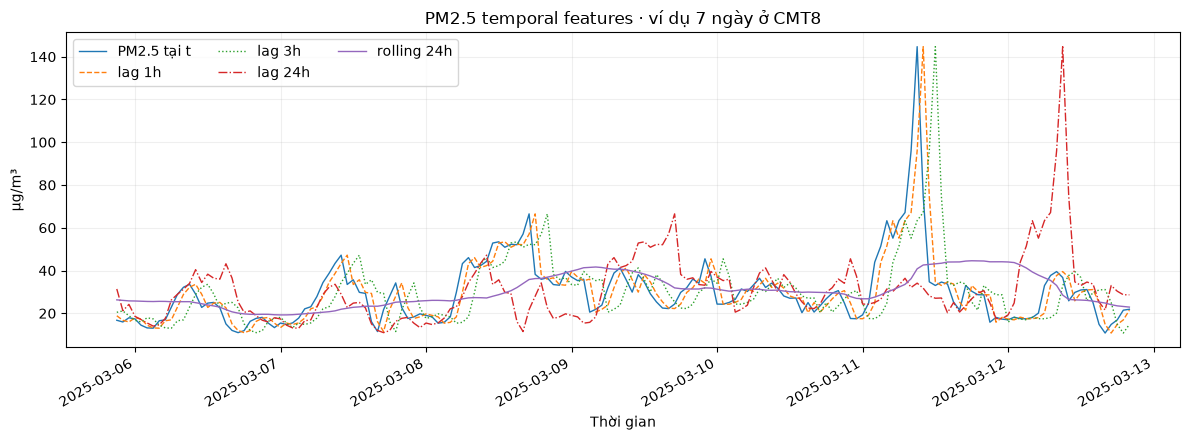

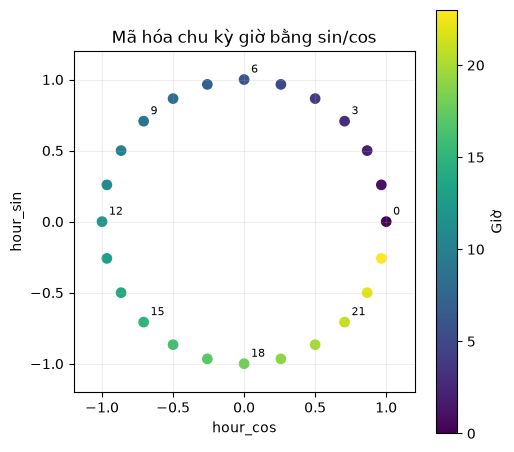

Candidate features: 19
- pm2_5_ug_m3_input_causal
- pm2_5_lag_1h
- pm2_5_lag_3h
- pm2_5_lag_24h
- pm2_5_rolling24h_mean
- pm1_ug_m3_input_causal
- pm1_ug_m3_lag_1h
- relative_humidity_pct_input_causal
- relative_humidity_pct_lag_1h
- temperature_c_input_causal
- temperature_c_lag_1h
- pm0_3_count_particles_cm3_input_causal
- pm0_3_count_particles_cm3_lag_1h
- hour_sin
- hour_cos
- day_of_week_sin
- day_of_week_cos
- month_sin
- month_cos


In [13]:
sample = cmt8.iloc[500:668].copy()  # 168 giờ
fig, ax = plt.subplots(figsize=(12, 4.5))
for col, label, style in [
    ("pm2_5_ug_m3", "PM2.5 tại t", "-"),
    ("pm2_5_lag_1h", "lag 1h", "--"),
    ("pm2_5_lag_3h", "lag 3h", ":"),
    ("pm2_5_lag_24h", "lag 24h", "-."),
    ("pm2_5_rolling24h_mean", "rolling 24h", "-"),
]: ax.plot(sample["datetime"], sample[col], lw=1, ls=style, label=label)
ax.set(title="PM2.5 temporal features · ví dụ 7 ngày ở CMT8", xlabel="Thời gian", ylabel="µg/m³")
ax.grid(alpha=.2); ax.legend(ncol=3); fig.autofmt_xdate(); fig.tight_layout(); plt.show()

hours = np.arange(24)
fig, ax = plt.subplots(figsize=(5.5,5.5))
sc = ax.scatter(np.cos(2*np.pi*hours/24), np.sin(2*np.pi*hours/24), c=hours, cmap="viridis", s=45)
for h in range(0,24,3):
    ax.annotate(str(h),(np.cos(2*np.pi*h/24),np.sin(2*np.pi*h/24)),xytext=(5,5),textcoords="offset points",fontsize=8)
ax.set_aspect("equal"); ax.set(xlim=(-1.2,1.2),ylim=(-1.2,1.2),title="Mã hóa chu kỳ giờ bằng sin/cos",xlabel="hour_cos",ylabel="hour_sin")
fig.colorbar(sc, ax=ax, label="Giờ"); ax.grid(alpha=.2); plt.show()

print("Candidate features:", len(CANDIDATE_FEATURE_COLUMNS))
print("\n".join(f"- {name}" for name in CANDIDATE_FEATURE_COLUMNS))

## 11. Tương quan candidate

- Chỉ dùng CMT8. Mốc train/validation/test được xác định theo `target_datetime` trên toàn timeline trước khi loại hàng thiếu
- Tương quan tính trên train với target quan sát được.
- Cách này tránh validation/test tham gia quyết định feature.

### 11.1. Xác định phạm vi train và chuẩn bị tương quan candidate

Ranh giới train/validation/test được xác định trên timeline trước khi loại hàng thiếu. Cell dưới chỉ dùng phần train để chuẩn bị tương quan giữa các candidate; kết quả sẽ được trình bày sau heatmap ở mục 11.3.


In [14]:
site = featured.loc[featured["location"].eq(MODELING_LOCATION)].copy().sort_values("datetime")
target_times = (site["target_datetime"].dropna()
                .drop_duplicates().sort_values().reset_index(drop=True))
train_end = min(max(int(len(target_times) * .70), 1), len(target_times) - 2)
validation_start = target_times.iloc[train_end]
test_start = target_times.iloc[min(max(int(len(target_times) * .85), train_end + 1), len(target_times)-1)]
train_observed = site.loc[
    (site["target_datetime"] < validation_start) & site[TARGET_COLUMN].notna(),
    CANDIDATE_FEATURE_COLUMNS + [TARGET_COLUMN],
]
print("Train period ends before:", validation_start)
print("Test period starts:", test_start)
print("Rows with observed target in train:", len(train_observed))

pearson = train_observed.corr(method="pearson", min_periods=30)
spearman = train_observed.corr(method="spearman", min_periods=30)
feature_corr_train = train_observed[CANDIDATE_FEATURE_COLUMNS].corr(method="pearson", min_periods=30)

Train period ends before: 2026-05-04 06:00:00+07:00
Test period starts: 2026-08-07 16:00:00+07:00
Rows with observed target in train: 10119


### 11.2. Heatmap tương quan giữa các candidate


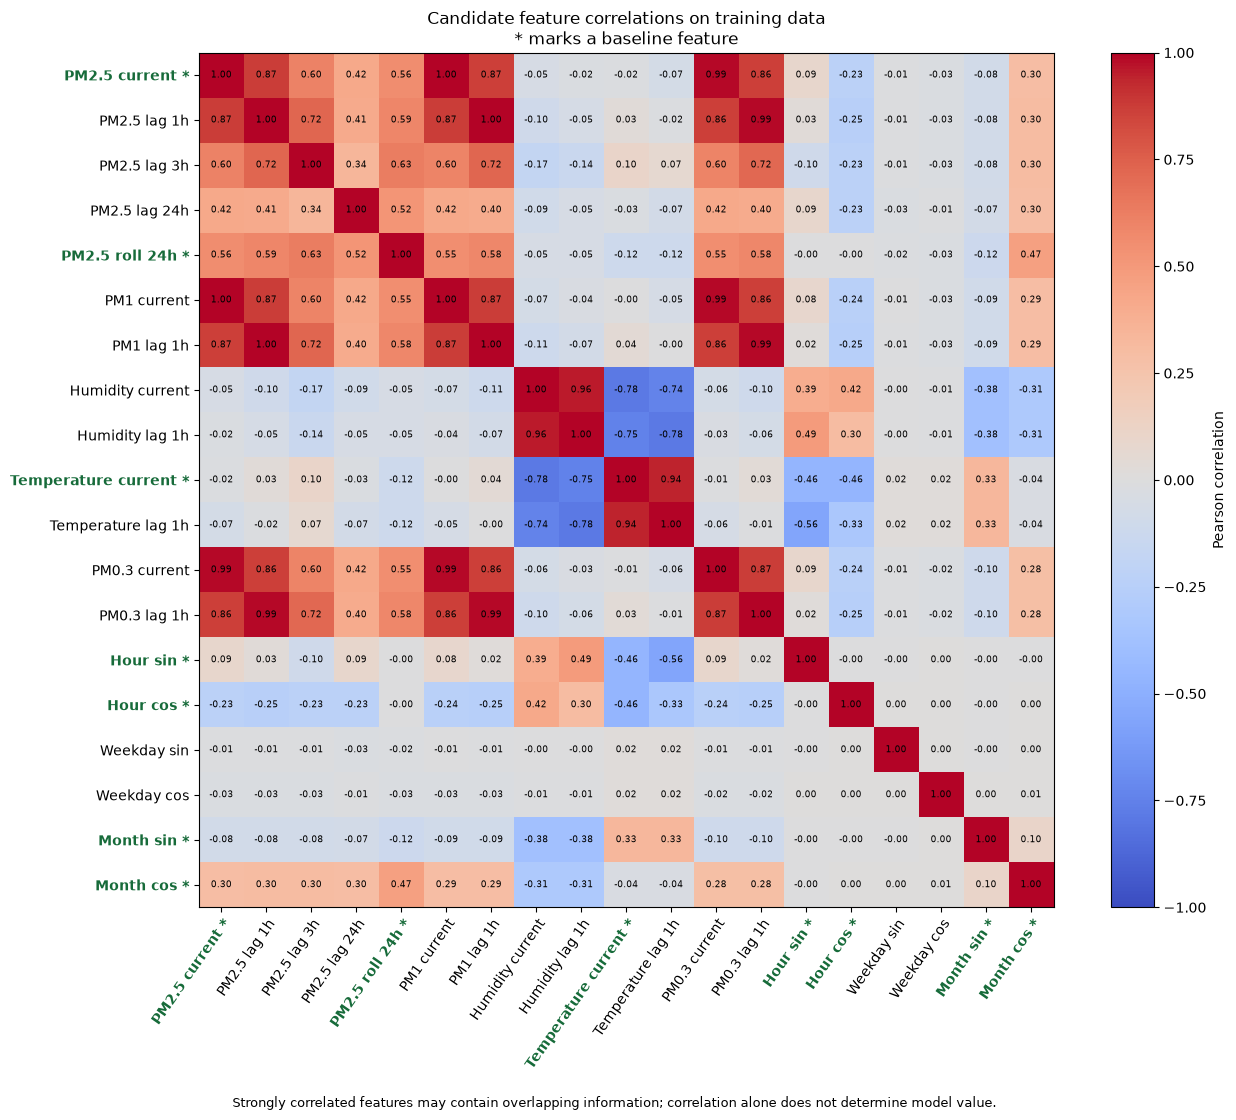

In [15]:
labels_by_feature = {
    "pm2_5_ug_m3_input_causal": "PM2.5 current",
    "pm2_5_lag_1h": "PM2.5 lag 1h",
    "pm2_5_lag_3h": "PM2.5 lag 3h",
    "pm2_5_lag_24h": "PM2.5 lag 24h",
    "pm2_5_rolling24h_mean": "PM2.5 roll 24h",
    "pm1_ug_m3_input_causal": "PM1 current",
    "pm1_ug_m3_lag_1h": "PM1 lag 1h",
    "relative_humidity_pct_input_causal": "Humidity current",
    "relative_humidity_pct_lag_1h": "Humidity lag 1h",
    "temperature_c_input_causal": "Temperature current",
    "temperature_c_lag_1h": "Temperature lag 1h",
    "pm0_3_count_particles_cm3_input_causal": "PM0.3 current",
    "pm0_3_count_particles_cm3_lag_1h": "PM0.3 lag 1h",
    "hour_sin": "Hour sin",
    "hour_cos": "Hour cos",
    "day_of_week_sin": "Weekday sin",
    "day_of_week_cos": "Weekday cos",
    "month_sin": "Month sin",
    "month_cos": "Month cos",
}
features = list(feature_corr_train.index)
selected_set = set(SELECTED_FEATURE_COLUMNS)
labels = [
    f"{labels_by_feature.get(feature, feature)} *" if feature in selected_set
    else labels_by_feature.get(feature, feature)
    for feature in features
]
size = max(11, len(features) * 0.72)
fig, ax = plt.subplots(figsize=(size, size * 0.82))
img = ax.imshow(feature_corr_train, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=55, ha="right", rotation_mode="anchor")
ax.set_yticks(range(len(labels)), labels)
for tick, feature in zip(ax.get_xticklabels(), features):
    if feature in selected_set:
        tick.set_color("#176b3a")
        tick.set_fontweight("bold")
for tick, feature in zip(ax.get_yticklabels(), features):
    if feature in selected_set:
        tick.set_color("#176b3a")
        tick.set_fontweight("bold")
for row in range(len(features)):
    for column in range(len(features)):
        value = feature_corr_train.iloc[row, column]
        label = "NA" if pd.isna(value) else f"{value:.2f}"
        ax.text(column, row, label, ha="center", va="center", fontsize=6.5)
ax.set_title("Candidate feature correlations on training data\n* marks a baseline feature")
fig.colorbar(img, ax=ax, label="Pearson correlation")
fig.text(
    0.5, 0.015,
    "Strongly correlated features may contain overlapping information; correlation alone does not determine model value.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()


**Nhận xét heatmap.** 
- PM2.5 hiện tại tương quan rất cao với PM1 hiện tại (**0.997**) và PM0.3 hiện tại (**0.989**), nên các biến này có thể mang thông tin chồng lấp.
- Nhiệt độ và độ ẩm cũng có liên hệ đáng chú ý (khoảng **−0.784**), nên cân nhắc tính dư thừa nếu đưa cả hai vào một baseline gọn.


### 11.3. Tương quan từng candidate với PM2.5 giờ kế tiếp


In [16]:
target_corr_rows=[]
for feature in CANDIDATE_FEATURE_COLUMNS:
    pair = train_observed[[feature, TARGET_COLUMN]].dropna()
    target_corr_rows.append({
        "feature": feature,
        "train_pairwise_rows": len(pair),
        "pearson_with_target": pearson.loc[feature, TARGET_COLUMN],
        "spearman_with_target": spearman.loc[feature, TARGET_COLUMN],
    })
feature_target_train = pd.DataFrame(target_corr_rows)
display(feature_target_train.sort_values("pearson_with_target", key=lambda s:s.abs(), ascending=False).round(3))

,feature,train_pairwise_rows,pearson_with_target,spearman_with_target
0,pm2_5_ug_m3_input_causal,10102,0.870,0.876
5,pm1_ug_m3_input_causal,10102,0.866,0.871
11,pm0_3_count_particles_cm3_input_causal,10102,0.862,0.869
1,pm2_5_lag_1h,10089,0.723,0.730
6,pm1_ug_m3_lag_1h,10089,0.718,0.722
12,pm0_3_count_particles_cm3_lag_1h,10089,0.717,0.721
4,pm2_5_rolling24h_mean,9969,0.522,0.531
2,pm2_5_lag_3h,10067,0.506,0.501
3,pm2_5_lag_24h,9969,0.401,0.459
18,month_cos,10119,0.297,0.281


**Nhận xét bảng tương quan.** 
- PM2.5 hiện tại có Pearson r **0.870** với target
- PM1 hiện tại (**0.866**) và PM0.3 hiện tại (**0.862**) cũng cao. 
- Rolling 24h đạt **0.522**, còn tương quan của lag 3h và 24h thấp hơn (**0.506** và **0.401**).
- Số cặp dùng để tính thay đổi theo feature do thiếu dữ liệu và quy tắc rolling.

=> Trên đây là liên hệ biên với target, chưa phản ánh đóng góp khi kết hợp nhiều biến.


#### Biểu đồ Pearson với target


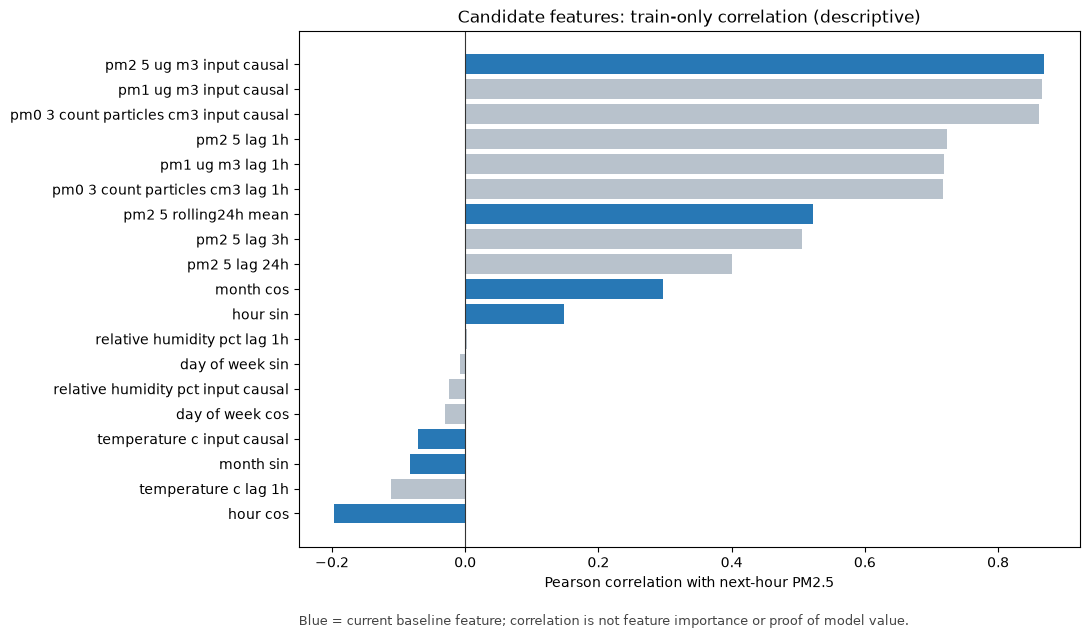

In [17]:
selected_set = set(SELECTED_FEATURE_COLUMNS)
ordered = feature_target_train.sort_values("pearson_with_target", na_position="first")
colors = ["#2878B5" if f in selected_set else "#B8C2CC" for f in ordered["feature"]]
labels = ordered["feature"].str.replace("_", " ", regex=False)
fig, ax = plt.subplots(figsize=(11, max(5, len(ordered) * 0.34)))
ax.barh(labels, ordered["pearson_with_target"], color=colors)
ax.axvline(0, color="#333333", linewidth=0.8)
ax.set_xlabel("Pearson correlation with next-hour PM2.5")
ax.set_title("Candidate features: train-only correlation (descriptive)")
ax.text(
    0, -0.13,
    "Blue = current baseline feature; correlation is not feature importance or proof of model value.",
    transform=ax.transAxes, ha="left", va="top", fontsize=9, color="#444444",
)
fig.tight_layout()
plt.show()


**Nhận xét biểu đồ.** PM2.5 hiện tại đứng đầu theo Pearson r với target (**0.870**); PM1 (**0.866**) và PM0.3 (**0.862**) cũng gần tương đương. Kết hợp với heatmap 11.2, điều này ủng hộ việc dùng PM2.5 hiện tại làm đại diện gọn cho nhóm phép đo bụi có tương quan chồng lấp. Rolling 24h (**0.522**) bổ sung tín hiệu nền lịch sử.

Màu xanh đánh dấu feature baseline đang cấu hình. Tương quan đơn biến không phải feature importance, không chứng minh cải thiện dự báo và không thay thế validation/ablation.


## 12. Chọn baseline

Không chọn theo thứ hạng tương quan đơn thuần. Dùng bốn tiêu chí: 
- **(1)** Có thể biết được tại thời điểm `t`
- **(2)** Đại diện cho tín hiệu hiện tại/lịch sử/khí tượng/chu kỳ có ý nghĩa
- **(3)** Tránh đưa đồng thời các biến gần trùng nhau
- **(4)** Mọi quyết định còn phải qua validation theo thời gian.

### Giữ trong baseline 7 biến

- **PM2.5 hiện tại:** tương quan với target khoảng **0.870**; có sẵn tại `t`, là tín hiệu trực tiếp nhất.
- **Rolling PM2.5 24h:** tương quan khoảng **0.522** thêm vào nhằm bổ sung mức nền 24h bên cạnh biến hiện tại, có độ phủ ở khoảng 95.96% hàng CMT8.
- **Nhiệt độ hiện tại:** tương quan đơn biến khoảng **−0.070**, yếu. Vẫn giữ như giả thuyết khí tượng do nguồn chỉ có nhiệt độ/độ ẩm. Validation/ablation sẽ quyết định giá trị thực.
- **Hour sin/cos:** giữ thành cặp để mô tả chu kỳ trong ngày; sin/cos riêng lẻ không nên chọn tách rời.
- **Month sin/cos:** giữ thành cặp để mô tả chu kỳ mùa/năm; dữ liệu gần 2 năm nên tính ổn định theo mùa cần được kiểm tra.

### Chưa đưa vào baseline, nhưng giữ làm candidate

- **PM1 và PM0.3 hiện tại:** tương quan với target cũng cao (xấp xỉ **0.866/0.862**), nhưng với PM2.5 hiện tại lần lượt khoảng **0.997/0.989** trong train. Chưa đưa vào baseline để tránh thông tin chồng lấp, tuy nhiên không kết luận chúng vô ích - hãy thử ablation.
- **PM2.5 lag 1h:** tương quan với target khoảng **0.723**, nhưng liên hệ với PM2.5 hiện tại khoảng **0.870**. Current value và rolling đã đại diện lịch sử gần, nên thử thêm lag ở ablation nếu có cơ sở.
- **PM2.5 lag 3h/24h:** tương quan target khoảng **0.506/0.401**, baseline quyết định giữ rolling thay vì nhiều lag rời rạc.
- **Độ ẩm:** tương quan target chỉ khoảng **−0.024**, tương quan với nhiệt độ khoảng **−0.784**. Hiện tạm bỏ để giảm redundancy, nhưng có thể thêm lại vì ý nghĩa vật lý.
- **Ngày trong tuần và lag khí tượng:** tương quan đơn biến yếu trong train nên chưa ưu tiên.
- **PM10:** thiếu 100% tại CMT8 nên không thể làm input baseline.

Đây không phải lựa chọn tự động được chứng minh tối ưu. Các tương quan là chẩn đoán và quyết định cuối cần dựa trên so sánh mô hình/ablation ở validation, không nên chỉ dựa riêng vào hệ số tương quan.

In [18]:
reason_map={}
for mapping in (FEATURE_SELECTION_REASONS, EXCLUDED_FEATURE_REASONS):
    for key, reason in mapping.items():
        for name in key.replace(" and ", "/").split("/"):
            reason_map[name]=reason
feature_decisions=pd.DataFrame({
    "feature": CANDIDATE_FEATURE_COLUMNS,
    "baseline_selected": [f in SELECTED_FEATURE_COLUMNS for f in CANDIDATE_FEATURE_COLUMNS],
    "train Pearson r": [feature_target_train.set_index("feature").loc[f,"pearson_with_target"] for f in CANDIDATE_FEATURE_COLUMNS],
    "selection rationale": [reason_map.get(f,"Candidate retained for diagnostics/ablation") for f in CANDIDATE_FEATURE_COLUMNS],
})
display(feature_decisions.round({"train Pearson r":3}))

,feature,baseline_selected,train Pearson r,selection rationale
0,pm2_5_ug_m3_input_causal,True,0.870,Latest observed or short-gap-filled PM2.5 valu...
1,pm2_5_lag_1h,False,0.723,Redundant with current PM2.5 in the training p...
2,pm2_5_lag_3h,False,0.506,Omitted from the compact baseline; rolling mea...
3,pm2_5_lag_24h,False,0.401,Omitted from the compact baseline; rolling mea...
4,pm2_5_rolling24h_mean,True,0.522,Recent PM2.5 background; uses raw observations...
5,pm1_ug_m3_input_causal,False,0.866,Strongly overlap with concurrent PM2.5; omitte...
6,pm1_ug_m3_lag_1h,False,0.718,Lagged particulate measures overlap with PM2.5...
7,relative_humidity_pct_input_causal,False,-0.024,Strongly correlated with temperature and has w...
8,relative_humidity_pct_lag_1h,False,0.003,Lagged humidity has a weak marginal target ass...
9,temperature_c_input_causal,True,-0.070,Available meteorological signal; kept as a can...


## 13. Tạo model-ready sau khi hoàn tất EDA và selection

Đến đây đã khảo sát dữ liệu, tạo candidate, xem tương quan train-only và chốt baseline provisional. Cell này để lọc CMT8, giữ 7 feature đã chọn, target PM2.5 đo thật và chia train/validation/test theo `target_datetime` (không shuffle).

,Rows,Share of model-ready (%)
split,,
train,9961,68.59
validation,2278,15.69
test,2284,15.73


Selected inputs: ['pm2_5_ug_m3_input_causal', 'pm2_5_rolling24h_mean', 'temperature_c_input_causal', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']
Target: target_pm2_5_next_hour
Total model-ready rows: 14523
Any missing in selected features/target: False
Validation starts: 2026-05-04T06:00:00+07:00
Test starts: 2026-08-07T16:00:00+07:00


,pm2_5_ug_m3_input_causal,pm2_5_rolling24h_mean,temperature_c_input_causal,hour_sin,hour_cos,month_sin,month_cos,target_pm2_5_next_hour,split
0,26.404875,26.992826,27.581417,-0.965926,0.258819,0.5,0.866025,28.082042,train
1,28.082042,27.050154,27.509208,-0.866025,0.500000,0.5,0.866025,28.660125,train
2,28.660125,27.130652,27.448208,-0.707107,0.707107,0.5,0.866025,26.245167,train
3,26.245167,27.088486,27.398166,-0.500000,0.866025,0.5,0.866025,27.934209,train
4,27.934209,27.126928,27.255500,-0.258819,0.965926,0.5,0.866025,31.388459,train


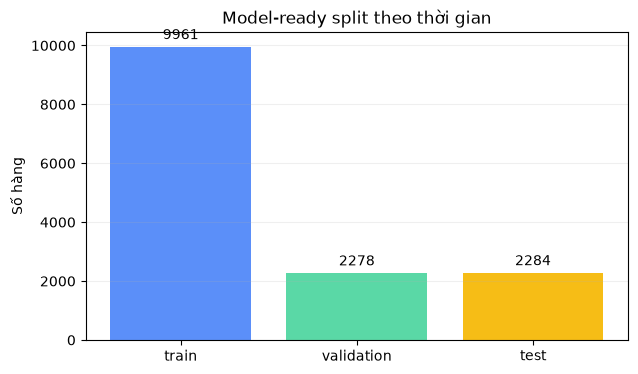

In [19]:
model_ready, pipeline_target_corr, pipeline_feature_corr, model_ready_report = prepare_model_ready_dataset(
    featured, location=MODELING_LOCATION
)
assert np.allclose(feature_corr_train, pipeline_feature_corr, equal_nan=True)
assert np.allclose(
    feature_target_train.set_index("feature").loc[CANDIDATE_FEATURE_COLUMNS,"pearson_with_target"].to_numpy(),
    pipeline_target_corr.set_index("feature").loc[CANDIDATE_FEATURE_COLUMNS,"pearson_with_target"].to_numpy(),
    equal_nan=True,
)

split_counts=model_ready["split"].value_counts().reindex(["train","validation","test"],fill_value=0)
display(pd.DataFrame({"Rows":split_counts,"Share of model-ready (%)":(100*split_counts/len(model_ready)).round(2)}))
print("Selected inputs:",SELECTED_FEATURE_COLUMNS)
print("Target:",TARGET_COLUMN)
print("Total model-ready rows:",len(model_ready))
print("Any missing in selected features/target:",bool(model_ready[SELECTED_FEATURE_COLUMNS+[TARGET_COLUMN]].isna().any().any()))
print("Validation starts:",model_ready_report["validation_start_target_datetime"])
print("Test starts:",model_ready_report["test_start_target_datetime"])
display(model_ready.head())
fig,ax=plt.subplots(figsize=(7,4))
bars=ax.bar(split_counts.index,split_counts.values,color=["#5B8FF9","#5AD8A6","#F6BD16"])
ax.bar_label(bars,padding=3); ax.set(title="Model-ready split theo thời gian",ylabel="Số hàng")
ax.grid(axis="y",alpha=.2); plt.show()